# Support Vector Machines on Telco Customer Churn

**Plan for this session**
1. Load the data
2. Explore it (EDA)
3. Prepare it for modelling (preprocessing)
4. Support Vector Machines

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

RANDOM_STATE = 42

## 1. Load the data

In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


Each row is one customer. `Churn` tells us whether the customer left (`Yes`) or stayed (`No`).
This is what we want to predict.

## 2. Exploratory Data Analysis (EDA)

### 2.1 Column types

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


`TotalCharges` should be a number, but it is stored as text (`object`). Let's see why.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")   # text that isn't a number becomes NaN

print("Missing values in TotalCharges:", df["TotalCharges"].isna().sum())
df[df["TotalCharges"].isna()][["tenure", "MonthlyCharges", "TotalCharges"]]

Missing values in TotalCharges: 11


,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


These customers have `tenure = 0`: they joined so recently that they haven't been billed yet. There are only a
handful of them, so we will drop them in preprocessing.

### 2.2 How many customers churn?

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn
No     0.735
Yes    0.265
Name: proportion, dtype: float64


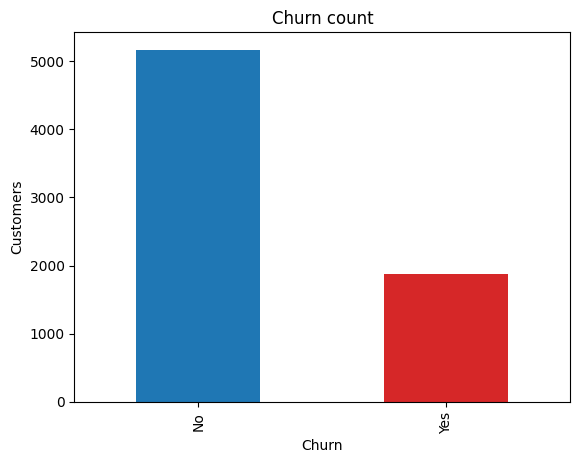

In [ ]:
print(df["Churn"].value_counts())
print()
print(df["Churn"].value_counts(normalize=True).round(3))

df["Churn"].value_counts().plot(kind="bar", color=["tab:blue", "tab:red"])
plt.title("Churn count")
plt.ylabel("Customers")
plt.show()

About **1 in 4** customers churn. The classes are **imbalanced**, so accuracy alone can mislead us: a model
that always says "No" would already be about 73% accurate. That is why we look at **precision, recall and F1**
for the churn class, and use `class_weight="balanced"` in the models.

### 2.3 Numeric columns: churners vs stayers

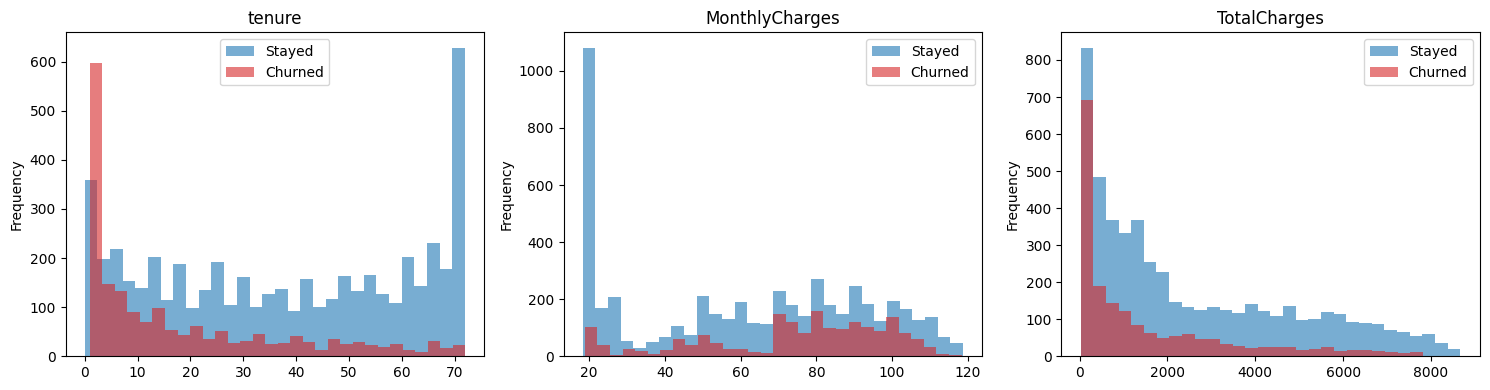

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.6,61.3,2555.3
Yes,18.0,74.4,1531.8


In [ ]:
numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numeric_columns):
    df[df["Churn"] == "No"][col].plot(kind="hist", bins=30, alpha=0.6, ax=ax, label="Stayed")
    df[df["Churn"] == "Yes"][col].plot(kind="hist", bins=30, alpha=0.6, ax=ax, label="Churned", color="tab:red")
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

df.groupby("Churn")[numeric_columns].mean().round(1)

**What we see**
* **tenure:** churners are mostly *new* customers. Long-time customers rarely leave.
* **MonthlyCharges:** churners tend to pay *more* per month.
* **TotalCharges:** churners have *lower* totals, mainly because they haven't been around long.

Also notice the **scales**: `tenure` goes up to 72, `TotalCharges` goes into the thousands. This matters for SVMs
).

### 2.4 Categorical columns: churn rate by group

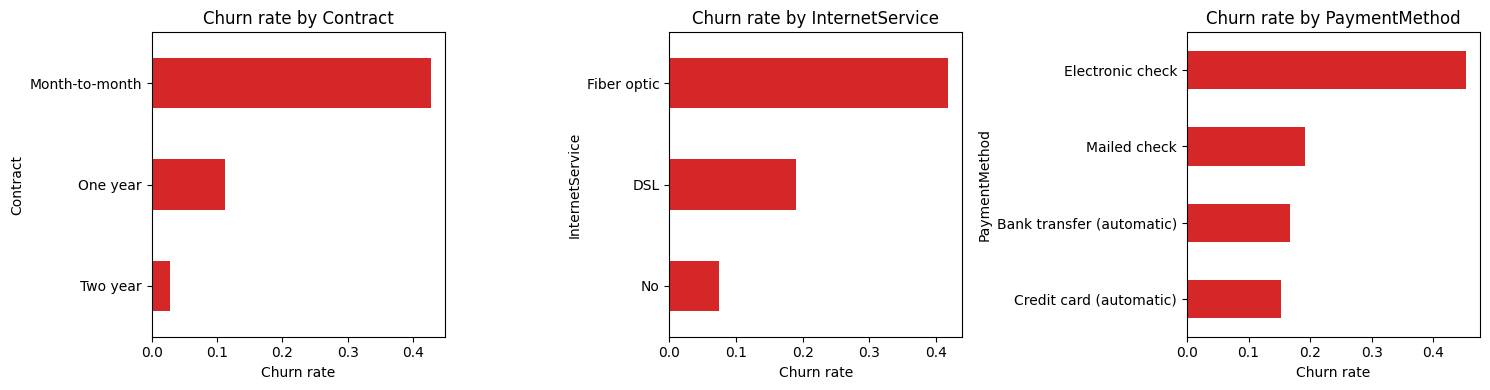

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    churn_rate = (df["Churn"] == "Yes").groupby(df[col]).mean().sort_values()
    churn_rate.plot(kind="barh", ax=ax, color="tab:red")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("Churn rate")
plt.tight_layout()
plt.show()

**What we see**
* **Month-to-month** contracts churn far more than one- or two-year contracts.
* **Fiber optic** internet customers churn more than DSL customers.
* Customers paying by **electronic check** churn the most.

These categorical columns will be useful features, but a model needs numbers, so next we convert them.

## 3. Data preprocessing

Steps:
1. Drop the rows with missing `TotalCharges` (found in 2.1).
2. Drop `customerID`: it is just a label and tells us nothing about churn.
3. Turn the target `Churn` into numbers: `Yes` → 1, `No` → 0.
4. **One-hot encode** the text columns, so each category becomes its own 0/1 column.
5. Split into train and test sets.
6. Checking for outliers
7. Scaling

In [ ]:
# Steps 1 and 2
df = df.dropna(subset=["TotalCharges"])
df = df.drop(columns=["customerID"])

# Step 3: target
y = (df["Churn"] == "Yes").astype(int)
X = df.drop(columns=["Churn"])

# Step 4: one-hot encode the text columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("X shape:", X.shape)
X.head()

X shape: (7032, 30)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


`drop_first=True` drops one category per column, because it can be worked out from the others
(for example, if `gender_Male` is 0, the customer is female).

In [ ]:
# Step 5: train/test split
# stratify=y keeps the same churn rate (about 26.6%) in both train and test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "  churn rate:", round(y_train.mean(), 3))
print("Test: ", X_test.shape,  "  churn rate:", round(y_test.mean(), 3))

Train: (5625, 30)   churn rate: 0.266
Test:  (1407, 30)   churn rate: 0.266



The score $\mathbf{w}^\top x$ adds the features together, so a feature measured in **thousands**
(`TotalCharges`) would swamp one measured in **tens** (`tenure`) purely because of its units, the SVM
would end up "listening" almost entirely to the large-scale column. The fix is to **standardise** each
numeric feature to mean $0$ and standard deviation $1$.


In [ ]:
# Step 6: Check for outliers
for col in numeric_columns:
    q1, q3 = X_train[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((X_train[col] < q1 - 1.5*iqr) | (X_train[col] > q3 + 1.5*iqr)).sum()
    print(f"{col:<15} outliers: {n_out}")

tenure          outliers: 0
MonthlyCharges  outliers: 0
TotalCharges    outliers: 0


In [ ]:
# Step 7: Scaling
# Scale ONLY the numeric columns (the one-hot columns are already 0/1).
scaler = StandardScaler()
X_train_svm = X_train.copy()
X_test_svm  = X_test.copy()

# Fit on train, then apply the SAME transform to test.
X_train_svm[numeric_columns] = scaler.fit_transform(X_train[numeric_columns])
X_test_svm[numeric_columns]  = scaler.transform(X_test[numeric_columns])



## 4. Support Vector Machines

A **Support Vector Machine** separates the two classes with a boundary, but not just any boundary.
Among all the lines that split churners from stayers, it chooses the one with the **widest empty gap**
on either side imagine paving the **widest possible street** down the middle of the two groups. The
centre line of that street is the **decision boundary**; the kerbs on each side are the **margins**.


## Why SVM?

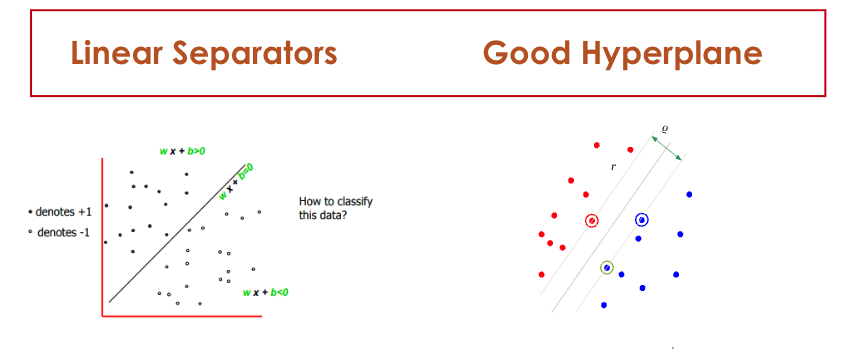

## What are support vectors and what is the objective?





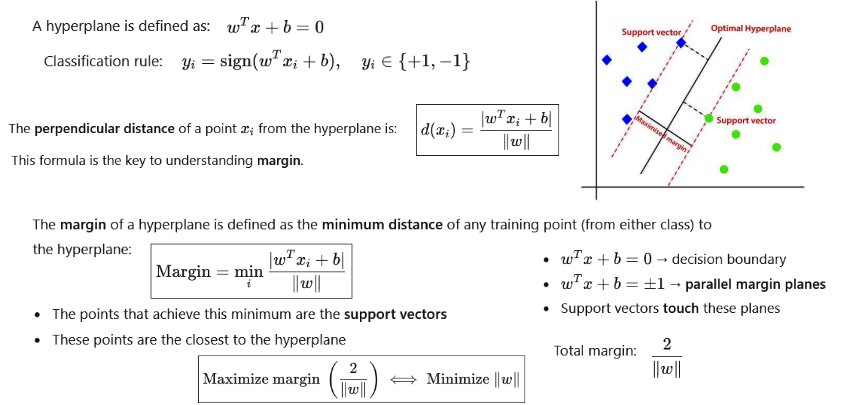




In [ ]:
def evaluate_svm(name, model):
    yhat_tr, yhat_te = model.predict(X_train_svm), model.predict(X_test_svm)

    def block(yt, yp):
        return (accuracy_score(yt, yp), precision_score(yt, yp),
                recall_score(yt, yp), f1_score(yt, yp))

    tr, te = block(y_train, yhat_tr), block(y_test, yhat_te)
    print(f"  {name}")
    print(f"  {'metric':<12}{'train':>8}{'test':>8}")
    for lbl, i in [("Accuracy", 0), ("Precision", 1), ("Recall", 2), ("F1 (Churn)", 3)]:
        print(f"  {lbl:<12}{tr[i]:>8.3f}{te[i]:>8.3f}")
    print(f"  {'F1 gap':<12}{'':>8}{tr[3] - te[3]:>8.3f}")

## Hard margin, soft margin, and the hinge loss

**Hard margin.** If the classes can be split by a straight line, we can insist that *every* point sit
on the correct side, past its margin:

$$ y_i(\mathbf{w}^\top x_i + b) \;\ge\; 1 \qquad \text{for every customer } i. $$

Maximising the margin then means: minimise $\tfrac{1}{2}\lVert \mathbf{w}\rVert^2$ subject to those
constraints. This is a **hard** margin (zero tolerance), no point may enter the street.

**Soft margin.** Real data overlaps, so a perfect separating line usually doesn't exist. We relax the
rule by giving each point a **slack** $\xi_i \ge 0$, how far it is allowed to fall short of its margin:

$$ y_i(\mathbf{w}^\top x_i + b) \;\ge\; 1 - \xi_i, \qquad \xi_i \ge 0, $$

and we minimise $\tfrac{1}{2}\lVert \mathbf{w}\rVert^2 + C\sum_i \xi_i$.

**The hinge loss.** That slack has a name. The penalty a single point pays is the **hinge loss**

$$ \ell\big(y, f(x)\big) \;=\; \max\!\big(0,\; 1 - y\,f(x)\big), $$

which is exactly the slack $\xi_i$: **zero** when the point is correct and beyond its margin, and
growing **linearly** the further it strays onto the wrong side. Putting it together, a soft-margin SVM
simply minimises

$$ \min_{\mathbf{w},\,b}\; \tfrac{1}{2}\lVert \mathbf{w}\rVert^{2}
\;+\; C \sum_i \max\!\big(0,\; 1 - y_i\,f(x_i)\big). $$


**`C` is the trade-off knob.** A **large** `C` makes slack expensive, so the model tolerates almost no
violations → a **hard**, narrow margin. A **small** `C` makes slack cheap, buying a **wider**, steadier
margin in exchange for a few violations. In other words `C` is a **regularisation** dial: turn it up and
the model tries to fit every training point; ease it down and it keeps the boundary simple.

The plots below shows the margin with and without slack: on the left (separable data) every
point satisfies $y_i(\mathbf{w}^\top x_i + b)\ge 1$, so all $\xi_i = 0$; on the right (overlapping data)
a few points need slack $\xi_i > 0$.



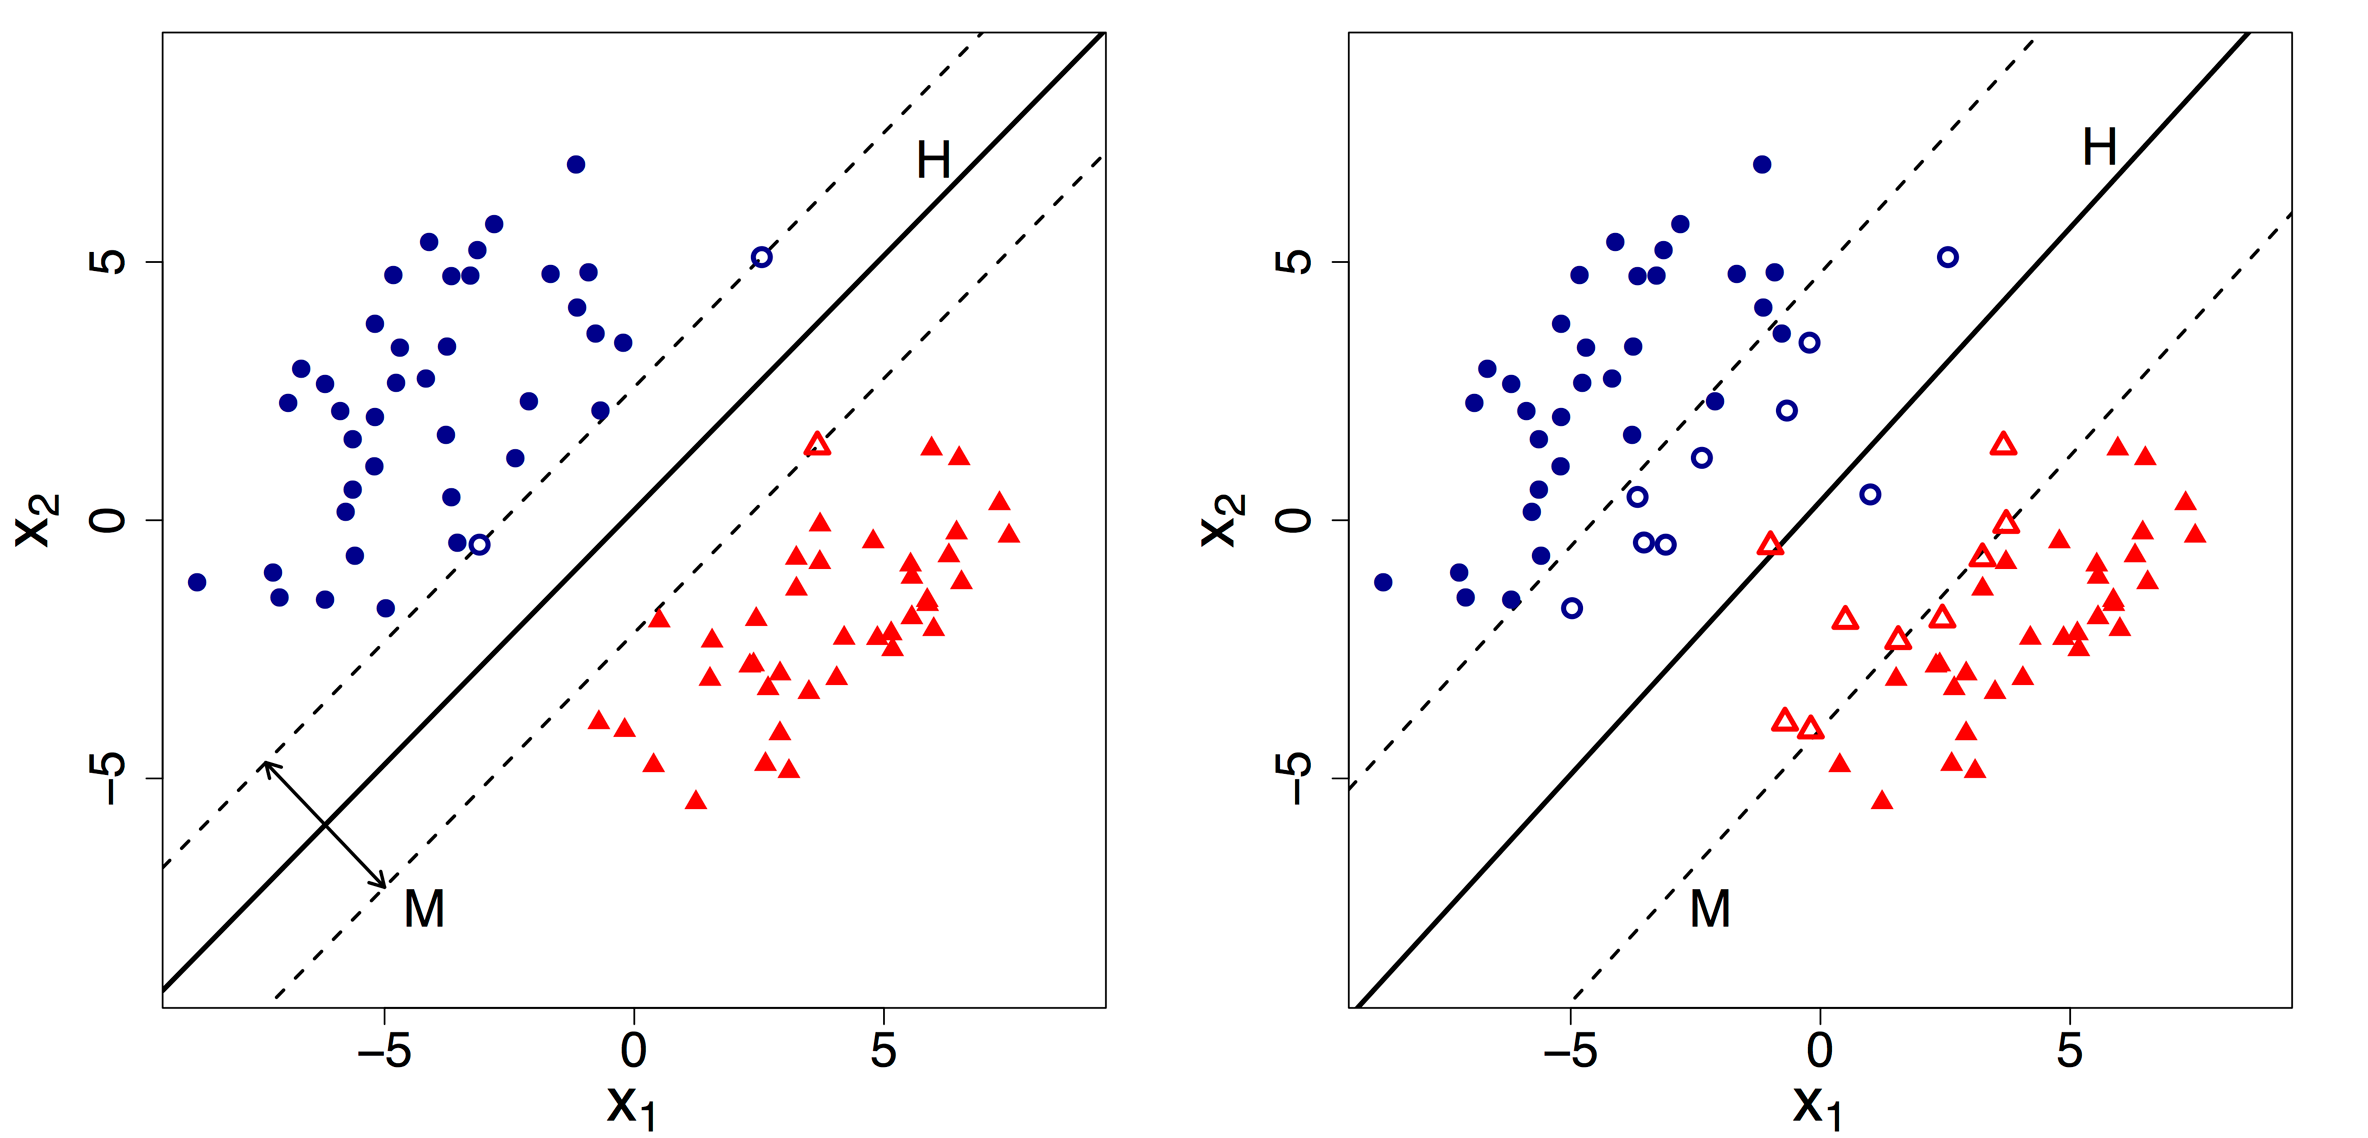

In [ ]:
from sklearn.svm import LinearSVC
from sklearn.svm import SVC


In [ ]:
# Hard Margin SVM - Linear Kernel
svm_hard_linear = LinearSVC(
    C=100000,
    loss = 'hinge',
    class_weight="balanced",
    random_state=RANDOM_STATE,
    max_iter = 200000
)

svm_hard_linear.fit(X_train_svm, y_train)
evaluate_svm("Hard SVM (Linear Kernel)", svm_hard_linear)

  Hard SVM (Linear Kernel)
  metric         train    test
  Accuracy       0.774   0.765
  Precision      0.605   0.575
  Recall         0.429   0.441
  F1 (Churn)     0.502   0.499
  F1 gap                 0.003


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


## What is Kernel ***Trick*** and why do we need it?

Many real-world datasets are not linearly separable in the original input space:


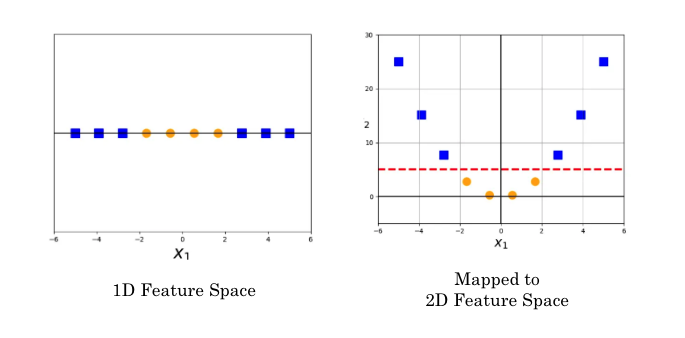


### Common Kernel Functions

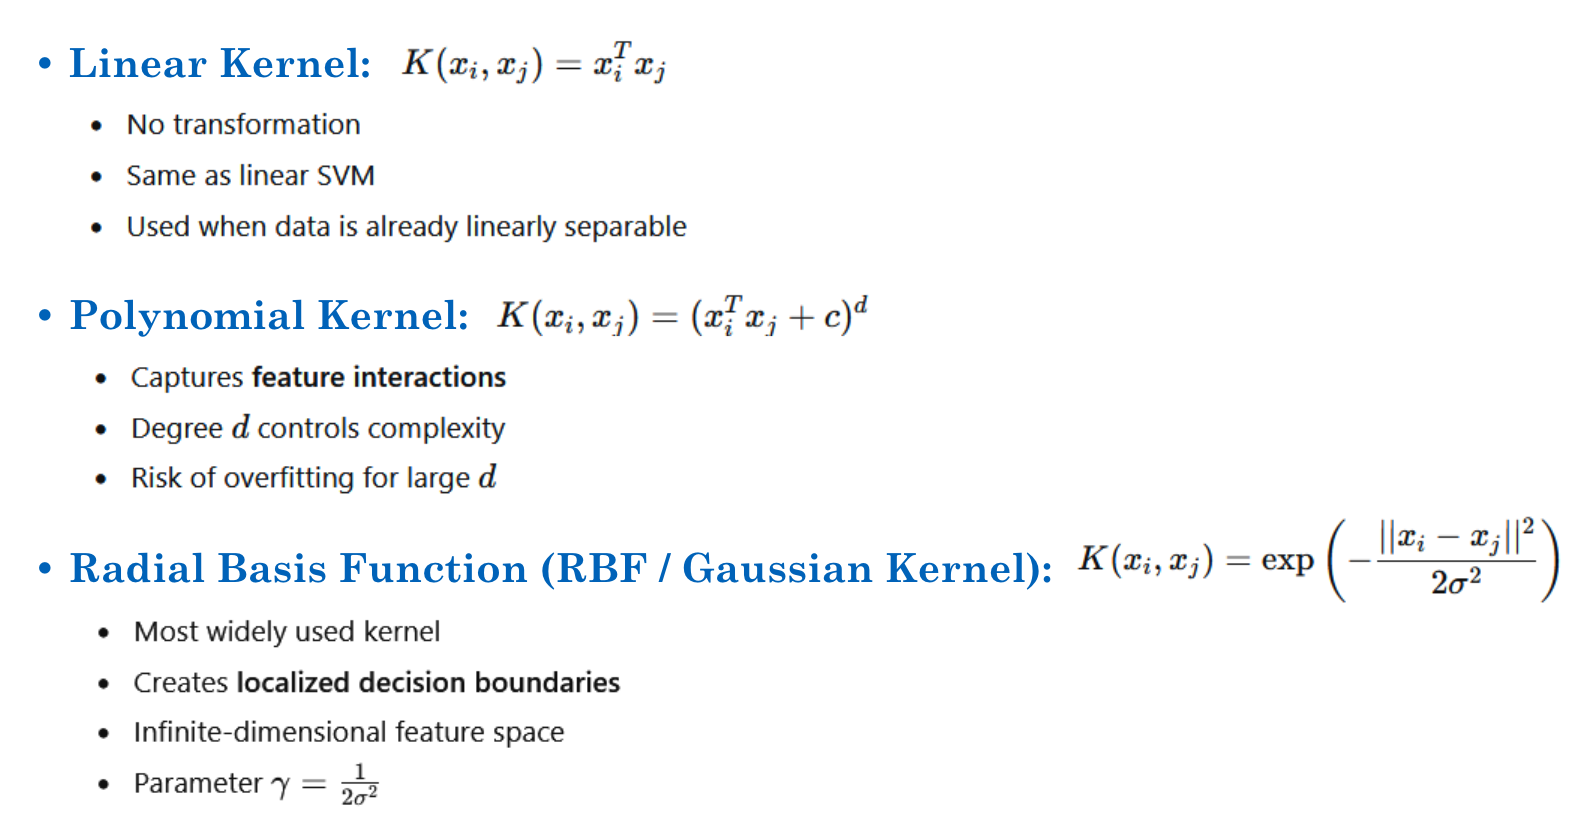

Gamma determines how quickly the similarity between two points decreases with distance.
- ** Small Gamma ** : Higher Bias, Lower Variance
- **Large Gamma ** :  Lower Bias, Higher Variance


In [ ]:
# Hard Margin SVM - Gaussian Kernel
svm_hard_rbf = SVC(
    kernel="rbf",
    C=1000,
    gamma="scale",
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

svm_hard_rbf.fit(X_train_svm, y_train)
evaluate_svm("Hard SVM (Gaussian Kernel)", svm_hard_rbf)

  Hard SVM (Gaussian Kernel)
  metric         train    test
  Accuracy       0.940   0.719
  Precision      0.828   0.477
  Recall         0.977   0.602
  F1 (Churn)     0.896   0.532
  F1 gap                 0.364


In [ ]:
# Soft Margin SVM - Linear Kernel
svm_soft_linear = LinearSVC(
    C=1,
    loss = 'hinge',
    class_weight="balanced",
    random_state=RANDOM_STATE,
    max_iter = 2000
)

svm_soft_linear.fit(X_train_svm, y_train)
evaluate_svm("Soft SVM (Linear Kernel)", svm_soft_linear)

  Soft SVM (Linear Kernel)
  metric         train    test
  Accuracy       0.704   0.687
  Precision      0.468   0.451
  Recall         0.837   0.816
  F1 (Churn)     0.600   0.580
  F1 gap                 0.020


In [ ]:
# Soft Margin SVM - Gaussian Kernel

svm_soft_rbf = SVC(
    kernel="rbf",
    C=1,
    gamma="scale",
    class_weight="balanced",
    random_state=RANDOM_STATE,
)

svm_soft_rbf.fit(X_train_svm, y_train)
evaluate_svm("Soft SVM (Gaussian Kernel)", svm_soft_rbf)

  Soft SVM (Gaussian Kernel)
  metric         train    test
  Accuracy       0.769   0.727
  Precision      0.543   0.492
  Recall         0.822   0.783
  F1 (Churn)     0.654   0.604
  F1 gap                 0.050


## Summary

| Setting | Train F1 | Test F1 | Train test F1 gap |
|---|---|---|---|
| **Hard margin** (`C = 1000`) - Linear Kernel    | 0.50 | 0.49 | 0.01 |
| **Hard margin** (`C = 1000`) - Gaussian Kernel   | 0.90 | 0.5 | 0.4 |
| **Soft margin** (`C = 1`) - Linear Kernel   | 0.60 | 0.58 | 0.02 |
| **Soft margin** (`C = 1`) - Gaussian Kernel  | 0.65 | 0.60 | 0.05 |


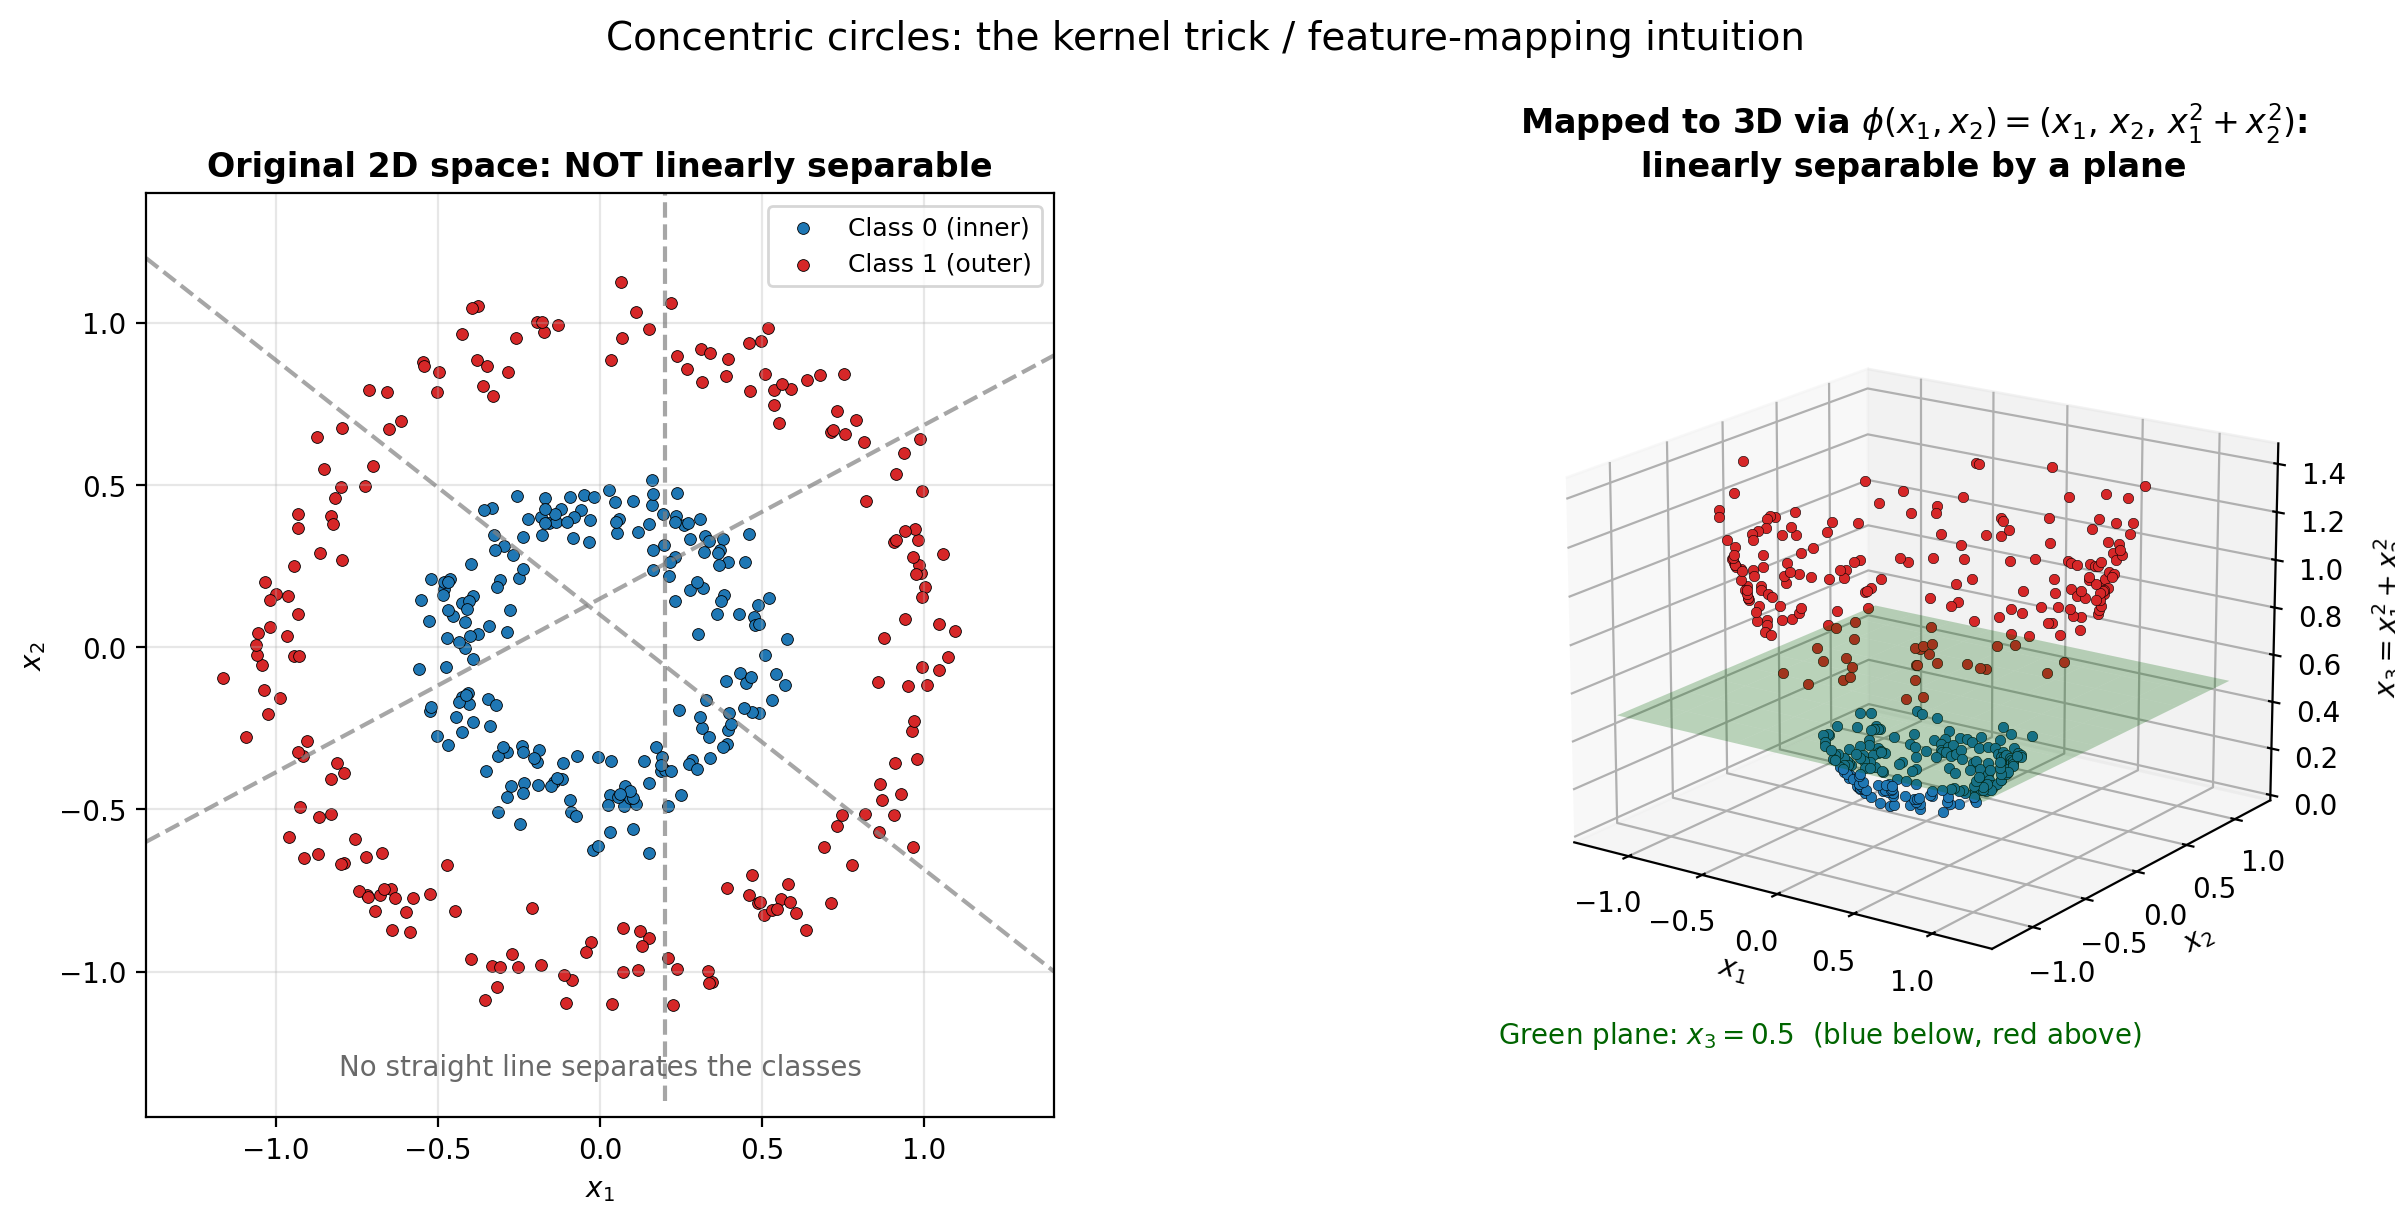

## Tuning `C` and `gamma` with cross-validation

So far we picked `C` and `gamma` by hand. Now we let **cross-validation** choose them:

* Split the training data into 5 parts (folds).
* For every combination of `C` and `gamma`: train on 4 folds, score F1 on the 5th, repeat 5 times, average.
* Pick the combination with the best **average validation F1**.

The test set is not used here at all. We touch it only once, at the very end.

**Why a pipeline?** We put the scaler *inside* the pipeline, so in every fold the scaler is fitted only on
that fold's training part. Otherwise the validation fold would leak into the scaling.

In [ ]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Same scaling as before: only the numeric columns; the one-hot columns pass through unchanged.
scaler_step = ColumnTransformer([("scale", StandardScaler(), numeric_columns)], remainder="passthrough")

pipe = Pipeline([
    ("scale", scaler_step),
    ("svm", SVC(kernel="rbf", class_weight="balanced", random_state=RANDOM_STATE)),
])

# The values to try. "svm__C" means: the C parameter of the step named "svm".
param_grid = {
    "svm__C":     [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1],
}

grid = GridSearchCV(
    pipe,
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="f1",
    return_train_score=True,   # also keep training scores, so we can see the train-validation gap
    n_jobs=-1,
)

grid.fit(X_train, y_train)    # raw X_train: the pipeline does the scaling itself

print("Best C and gamma :", grid.best_params_)
print("Best CV F1       :", round(grid.best_score_, 3))

Best C and gamma : {'svm__C': 1, 'svm__gamma': 0.1}
Best CV F1       : 0.626


### All 16 combinations

`gap` = train F1 − validation F1. A big gap means the model is memorising the training data (high variance).

In [ ]:
results = pd.DataFrame(grid.cv_results_)
results = results[["param_svm__C", "param_svm__gamma", "mean_train_score", "mean_test_score"]]
results.columns = ["C", "gamma", "train F1", "validation F1"]
results["gap"] = (results["train F1"] - results["validation F1"]).round(3) + 0.0

results.sort_values(["C", "gamma"], ascending=False).round(3)

,C,gamma,train F1,validation F1,gap
15,100.0,1.000,0.943,0.498,0.444
14,100.0,0.100,0.834,0.562,0.272
13,100.0,0.010,0.647,0.622,0.026
12,100.0,0.001,0.600,0.600,0.000
11,10.0,1.000,0.917,0.505,0.412
10,10.0,0.100,0.727,0.605,0.122
9,10.0,0.010,0.619,0.616,0.003
8,10.0,0.001,0.625,0.622,0.003
7,1.0,1.000,0.878,0.579,0.299
6,1.0,0.100,0.655,0.626,0.029


**What to look for**
* **Large `C` and large `gamma`** (bottom of the table): high train F1, low validation F1, big gap. The model
  is too flexible: **high variance**.
* **Small `C` and small `gamma`**: tiny gap, but validation F1 is a bit lower. The model is a little too
  simple: **higher bias**.
* The best combination sits in between.

### Final check on the test set

In [ ]:
best_model = grid.best_estimator_

yhat_tr = best_model.predict(X_train)
yhat_te = best_model.predict(X_test)

print(f"{'metric':<12}{'train':>8}{'test':>8}")
for name, metric in [("Accuracy", accuracy_score), ("Precision", precision_score),
                     ("Recall", recall_score), ("F1 (Churn)", f1_score)]:
    print(f"{name:<12}{metric(y_train, yhat_tr):>8.3f}{metric(y_test, yhat_te):>8.3f}")
print(f"{'F1 gap':<12}{'':>8}{f1_score(y_train, yhat_tr) - f1_score(y_test, yhat_te):>8.3f}")

metric         train    test
Accuracy       0.766   0.730
Precision      0.540   0.495
Recall         0.817   0.786
F1 (Churn)     0.650   0.607
F1 gap                 0.043
